# 02 · Training curves

Loss and validation metrics per epoch for the two fine-tuned transformers, read from the
training logs in `runs/` (also viewable with `tensorboard --logdir runs`). Epoch 1 is the
frozen-encoder phase (head only); epochs 2–4 fine-tune the whole network.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["TQDM_DISABLE"] = "1"  # no progress bars in the rendered notebook
warnings.filterwarnings("ignore", category=UserWarning)

# Notebooks run with notebooks/ as the working directory; make `src` importable.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import plots
from src.config import LABELS, RUNS_DIR

plots.apply_theme()
pd.set_option("display.precision", 4)

In [2]:
RUNS = {"BERT-base": "20261012-183051", "RoBERTa-base": "roberta-base"}

rows = []
for name, run in RUNS.items():
    history = json.loads((RUNS_DIR / run / "history.json").read_text())
    for epoch in history["history"]:
        rows.append({"model": name, "epoch": epoch["epoch"], "phase": epoch["phase"],
                     "train_loss": epoch["train_loss"], "val_loss": epoch["val_loss"],
                     "val_accuracy": epoch["accuracy"], "val_auc_roc": epoch["auc_roc"],
                     "val_macro_f1": epoch["macro_f1"],
                     **{f"recall_{k}": v for k, v in epoch["recall"].items()},
                     "minutes": epoch["minutes"]})
curves = pd.DataFrame(rows)
curves

,model,epoch,phase,train_loss,val_loss,val_accuracy,val_auc_roc,val_macro_f1,recall_negative,recall_neutral,recall_positive,minutes
0,BERT-base,1,frozen,0.8265,0.7337,0.7467,0.8686,0.5917,0.7624,0.4674,0.7871,2.92
1,BERT-base,2,finetune,0.6526,0.5627,0.8224,0.9325,0.7004,0.7532,0.6749,0.8519,7.33
2,BERT-base,3,finetune,0.4629,0.6430,0.8477,0.9351,0.7117,0.7882,0.5992,0.8915,7.32
3,BERT-base,4,finetune,0.2988,0.8062,0.8497,0.9356,0.7187,0.7330,0.6436,0.8932,7.33
4,RoBERTa-base,1,frozen,1.0439,1.0103,0.8120,0.8677,0.6166,0.6998,0.3721,0.8903,2.93
5,RoBERTa-base,2,finetune,0.6409,0.5233,0.8511,0.9469,0.7305,0.7274,0.7193,0.8842,7.41
6,RoBERTa-base,3,finetune,0.4771,0.5470,0.8554,0.9466,0.7291,0.8029,0.6462,0.8924,7.42
7,RoBERTa-base,4,finetune,0.3528,0.6534,0.8579,0.9454,0.7350,0.7532,0.6867,0.8948,7.40


## 1. Loss — BERT-base and RoBERTa-base

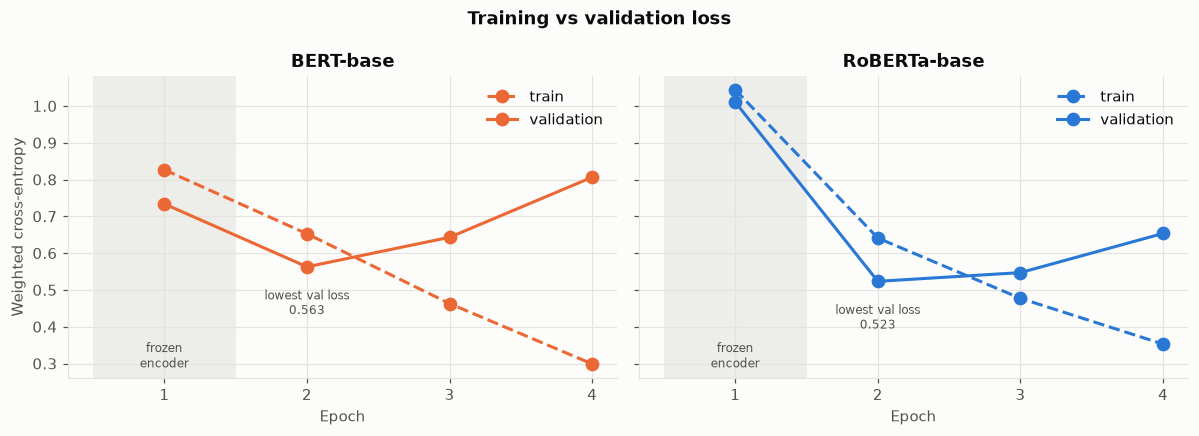

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, frame) in zip(axes, curves.groupby("model", sort=False)):
    color = plots.MODEL_COLORS[name]
    ax.axvspan(0.5, 1.5, color=plots.GRID, alpha=0.6, lw=0)
    ax.text(1, 0.02, "frozen\nencoder", transform=ax.get_xaxis_transform(), ha="center",
            va="bottom", fontsize=8, color=plots.INK_SECONDARY)
    ax.plot(frame.epoch, frame.train_loss, ls="--", marker="o", color=color, label="train")
    ax.plot(frame.epoch, frame.val_loss, ls="-", marker="o", color=color, label="validation")
    best = frame.loc[frame.val_loss.idxmin()]
    ax.annotate(f"lowest val loss\n{best.val_loss:.3f}", (best.epoch, best.val_loss),
                xytext=(0, -14), textcoords="offset points", ha="center", va="top", fontsize=8,
                color=plots.INK_SECONDARY)
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_xticks(frame.epoch)
    ax.legend(loc="upper right")
axes[0].set_ylabel("Weighted cross-entropy")
fig.suptitle("Training vs validation loss", fontweight="bold")
fig.tight_layout()
plots.save(fig, "w2_loss_curves")
plt.show()

## 2. Validation macro-F1 — BERT-base vs RoBERTa-base (the model-selection metric)

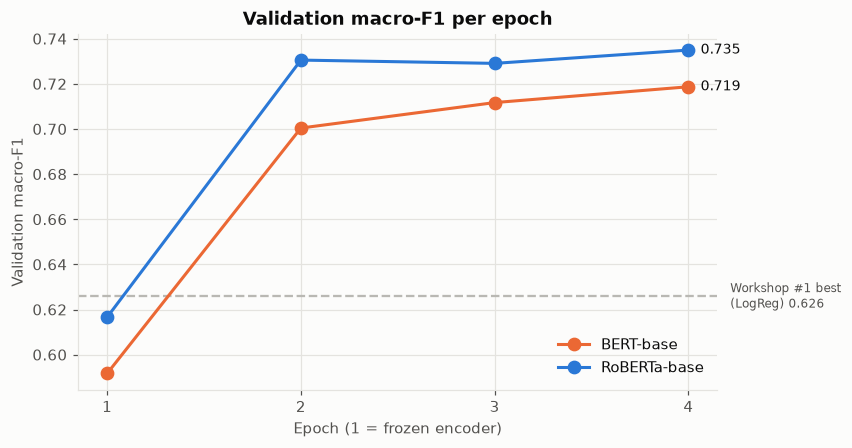

In [4]:
baselines = json.loads((RUNS_DIR / "workshop1_baselines.json").read_text())
logreg_val = baselines["validation"]["Logistic Regression"]["macro_f1"]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.axhline(logreg_val, color=plots.MUTED, ls="--", lw=1.5)
ax.text(1.02, logreg_val, f"Workshop #1 best\n(LogReg) {logreg_val:.3f}", va="center",
        fontsize=8, color=plots.INK_SECONDARY, transform=ax.get_yaxis_transform())
for name, frame in curves.groupby("model", sort=False):
    color = plots.MODEL_COLORS[name]
    ax.plot(frame.epoch, frame.val_macro_f1, marker="o", color=color, label=name)
    last = frame.iloc[-1]
    ax.annotate(f"{last.val_macro_f1:.3f}", (last.epoch, last.val_macro_f1), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=plots.INK)
ax.set_xticks(sorted(curves.epoch.unique()))
ax.set_xlabel("Epoch (1 = frozen encoder)")
ax.set_ylabel("Validation macro-F1")
ax.set_title("Validation macro-F1 per epoch")
ax.legend(loc="lower right")
plots.save(fig, "w2_val_macro_f1")
plt.show()

## 3. Per-class recall on validation — RoBERTa-base

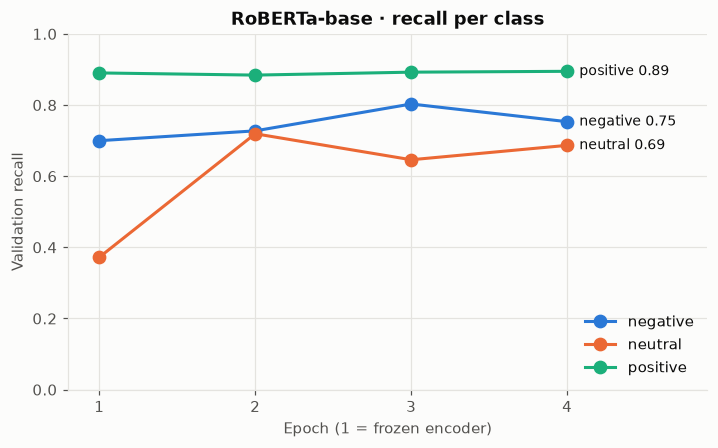

In [5]:
frame = curves[curves.model == "RoBERTa-base"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for label in LABELS:
    ax.plot(frame.epoch, frame[f"recall_{label}"], marker="o",
            color=plots.CLASS_COLORS[label], label=label)
    last = frame.iloc[-1]
    ax.annotate(f"{label} {last[f'recall_{label}']:.2f}", (last.epoch, last[f"recall_{label}"]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xticks(frame.epoch)
ax.set_xlim(0.8, 4.9)
ax.set_ylim(0, 1)
ax.set_xlabel("Epoch (1 = frozen encoder)")
ax.set_ylabel("Validation recall")
ax.set_title("RoBERTa-base · recall per class")
ax.legend(loc="lower right")
plots.save(fig, "w2_recall_per_class_epochs")
plt.show()

## 4. Training cost — BERT-base and RoBERTa-base

In [6]:
curves.groupby("model", sort=False).agg(epochs=("epoch", "max"),
                                       total_minutes=("minutes", "sum"),
                                       best_val_macro_f1=("val_macro_f1", "max"))

,epochs,total_minutes,best_val_macro_f1
model,,,
BERT-base,4,24.90,0.7187
RoBERTa-base,4,25.16,0.7350


## Findings

- **The pretrained encoder already knows a lot.** With the encoder frozen (epoch 1, 2,307
  trainable parameters) RoBERTa reaches **0.617** validation macro-F1, almost the
  **0.626** of the best Workshop #1 model, which needed a hand-built TF-IDF pipeline.
- **Fine-tuning brings the big jump.** Unfreezing the encoder adds **+0.114** macro-F1 in
  one epoch for RoBERTa (0.617 → 0.731) and **+0.109** for BERT (0.592 → 0.700).
- **Both models overfit after epoch 2.** Validation loss is lowest at epoch 2
  (RoBERTa 0.523, BERT 0.563) and then rises (to 0.653 and 0.806) while training loss
  keeps falling. Macro-F1 still creeps up (RoBERTa +0.005 from epoch 2 to 4, within the
  ~3-point noise band measured in Workshop #1): the models get *more confident*, not
  *more correct*. This is why the brief's 10–20 fine-tuning epochs were cut to 3.
- **Neutral is the unstable class.** Its recall swings 0.37 → 0.72 → 0.65 → 0.69 as the
  model trades neutral against negative and positive; the extremes stay stable.
- **RoBERTa beats BERT at every epoch**, by 1.6 points at the end, at the same cost
  (about 25 minutes each on an AMD RX 9060 XT).